![](img/banner.png)

# Brute force search clustering

**Mahmood Amintoosi, Fall 2026**

Computer Science Dept, Ferdowsi University of Mashhad


## The idea

In [Clustering-Part1](Clustering-Part1.ipynb) it was said that trying every
possible clustering is infeasible. Here we do exactly that, for $k=2$ clusters
and a handful of points, because it gives the **exact optimum**; and the exact
optimum is the only honest way to say whether a heuristic such as k-means did
well or badly.

The recipe is short:

1. enumerate all labelings of the $n$ points with the labels 0 and 1;
2. discard the labelings that do not describe two non-empty clusters;
3. score the rest with a cost, here the within-cluster sum of squares;
4. keep the minimum.

Step 1 is the recursion of the [SAT-Table](SAT-Table.ipynb) notebook, so we
start by recalling it.

## 1. Enumerating labelings


In [1]:
def labelings_2(x, i=0):
    """All 0/1 vectors of length len(x), one at a time."""
    if i == len(x):
        yield list(x)               # a copy, not the shared buffer
    else:
        for x[i] in range(2):
            yield from labelings_2(x, i + 1)


for z in labelings_2([0, 0, 0]):
    print(z)


[0, 0, 0]
[0, 0, 1]
[0, 1, 0]
[0, 1, 1]
[1, 0, 0]
[1, 0, 1]
[1, 1, 0]
[1, 1, 1]


Eight rows, as expected: $2^3$. But not all of them are clusterings.

## 2. From a labeling to a clustering

A labeling is a vector of labels; a clustering is a list of blocks that contain
*indices* of points. The conversion is a list comprehension over the labels:


In [2]:
def to_clusters(z):
    """[0, 1, 1, 0] -> [[0, 3], [1, 2]] : the point indices of each cluster."""
    k = max(z) + 1
    return [[i for i, label in enumerate(z) if label == b] for b in range(k)]


In [3]:
for z in labelings_2([0, 0, 0]):
    print(z, "->", to_clusters(z))


[0, 0, 0] -> [[0, 1, 2]]
[0, 0, 1] -> [[0, 1], [2]]
[0, 1, 0] -> [[0, 2], [1]]
[0, 1, 1] -> [[0], [1, 2]]
[1, 0, 0] -> [[1, 2], [0]]
[1, 0, 1] -> [[1], [0, 2]]
[1, 1, 0] -> [[2], [0, 1]]
[1, 1, 1] -> [[], [0, 1, 2]]


Two of the eight labelings, `[0,0,0]` and `[1,1,1]`, use a single label: they
describe **one** cluster, not two. The other six come in pairs such as
`[0,1,1]` and `[1,0,0]`, which describe the *same* split $\{1\}|\{2,3\}$ with the
names of the clusters swapped. Since we are looking for partitions and not
labelings, we keep one of each pair:


In [4]:
def clusterings_2(n):
    """All partitions of {0,...,n-1} into exactly two non-empty blocks."""
    for z in labelings_2([0] * n):
        blocks = to_clusters(z)
        if len(blocks) < 2 or len(blocks[0]) == 0 or len(blocks[1]) == 0:
            continue
        if 0 not in blocks[0]:          # keep only one of the two labelings
            continue
        yield blocks


for blocks in clusterings_2(3):
    print(blocks)


[[0, 1], [2]]
[[0, 2], [1]]
[[0], [1, 2]]


## 3. How many candidates? $2^n$ or $2^{n-1}-1$?

The number of 0/1 vectors is $2^n$. Half of them are complements of the other
half (the same partition with the labels swapped) and two are constant (one
cluster). What remains is

$$S(n,2) = 2^{n-1}-1,$$

the Stirling number of the second kind from the SAT-Table notebook. Counting the
output of the generator confirms both the formula and the code:


In [5]:
for n in range(2, 11):
    produced = sum(1 for _ in clusterings_2(n))
    print(f"n = {n:>2}   produced = {produced:>5}   2**(n-1) - 1 = {2 ** (n - 1) - 1:>5}")


n =  2   produced =     1   2**(n-1) - 1 =     1
n =  3   produced =     3   2**(n-1) - 1 =     3
n =  4   produced =     7   2**(n-1) - 1 =     7
n =  5   produced =    15   2**(n-1) - 1 =    15
n =  6   produced =    31   2**(n-1) - 1 =    31
n =  7   produced =    63   2**(n-1) - 1 =    63
n =  8   produced =   127   2**(n-1) - 1 =   127
n =  9   produced =   255   2**(n-1) - 1 =   255
n = 10   produced =   511   2**(n-1) - 1 =   511


In [6]:
for n in [5, 10, 20, 30, 40, 50]:
    print(f"n = {n:>2}   labelings = {2 ** n:>17}   clusterings = {2 ** (n - 1) - 1:>17}")


n =  5   labelings =                32   clusterings =                15
n = 10   labelings =              1024   clusterings =               511
n = 20   labelings =           1048576   clusterings =            524287
n = 30   labelings =        1073741824   clusterings =         536870911
n = 40   labelings =     1099511627776   clusterings =      549755813887
n = 50   labelings =  1125899906842624   clusterings =   562949953421311


The right-hand column is the number of *candidate solutions* of the 2-clustering
problem, and it doubles with every new point. For $n=50$ it is already
$5.6\times10^{14}$; for the $n=60\,000$ pixels of a small image it is a number
with 18 000 digits.

## 4. The cost: within-cluster sum of squares

We need a number that says how good a clustering is. The standard choice (see
[Clustering-Part2](Clustering-Part2.ipynb)) is the **within-cluster sum of
squares**: for a cluster $C$ with centroid $\boldsymbol\mu_C$,

$$
W(C) = \sum_{\mathbf{x}\in C}\|\mathbf{x}-\boldsymbol\mu_C\|^2,
\qquad
\text{cost}(\mathcal{C}) = \sum_{j=1}^{k} W(C_j).
$$

It is also called SSE (sum of squared errors) or WCSS. A point is a tuple of
coordinates, so a 1-D data set is simply a set of 1-tuples such as `(10,)`.
Writing the code for tuples from the beginning means that nothing changes when
the data become 2-D or 20-D.


In [7]:
import math


def sq_dist(a, b):
    """Squared Euclidean distance between two points (tuples of equal length)."""
    return sum((ai - bi) ** 2 for ai, bi in zip(a, b))


def dist(a, b):
    return math.sqrt(sq_dist(a, b))


def centroid(C):
    """Coordinate-wise mean of a list of points."""
    m = len(C)
    return tuple(sum(p[d] for p in C) / m for d in range(len(C[0])))


def wcss(D, idx):
    """Within-cluster sum of squares of the points of D selected by idx."""
    if not idx:
        return 0.0
    C = [D[i] for i in idx]
    mu = centroid(C)
    return sum(sq_dist(p, mu) for p in C)


**A remark that saves half the work.** There is a second way to write the same
quantity: sum the squared distances over all *pairs* inside the cluster. Lemma 2
of [Clustering-Part2](Clustering-Part2.ipynb) says

$$
\sum_{i<j}\|\mathbf{x}_i-\mathbf{x}_j\|^2
= |C|\sum_{i}\|\mathbf{x}_i-\boldsymbol\mu_C\|^2 = |C|\,W(C).
$$

So the pairwise sum and $W(C)$ differ only by the factor $|C|$, and minimizing
one minimizes the other. The centroid form costs $O(|C|)$ per cluster and the
pairwise form $O(|C|^2)$, so the centroid form is the one to use. Checking the
identity is a good test of both functions:


In [8]:
def wcss_pairs(D, idx):
    C = [D[i] for i in idx]
    return sum(sq_dist(a, b) for i, a in enumerate(C) for b in C[i + 1:])


D = [(10,), (11,), (20,), (23,)]
idx = [0, 1, 2]
print("centroid form :", wcss(D, idx))
print("pairwise form :", wcss_pairs(D, idx))
print("|C| * W(C)    :", len(idx) * wcss(D, idx))


centroid form : 60.66666666666667
pairwise form : 182
|C| * W(C)    : 182.0


## 5. Brute force

The four steps of the introduction are now three lines of code.


In [9]:
def bf_clustering_2(D):
    """Exact 2-clustering: minimize the total within-cluster sum of squares."""
    best_cost, best = math.inf, None
    for blocks in clusterings_2(len(D)):
        cost = sum(wcss(D, block) for block in blocks)
        if cost < best_cost:
            best_cost, best = cost, blocks
    return best, best_cost


D = [(10,), (20,), (23,)]
best, best_cost = bf_clustering_2(D)
print("best clustering:", [[D[i][0] for i in block] for block in best])
print("cost:", best_cost)


best clustering: [[10], [20, 23]]
cost: 4.5


The answer is $\{10\}$ together with $\{20,23\}$: the two close points share a
cluster. The exhaustive search reports the *global* optimum, not a local one.

Looking at all the candidates and their costs shows the objective landscape:


In [10]:
D = [(10,), (20,), (23,)]
for z in labelings_2([0, 0, 0]):
    blocks = to_clusters(z)
    cost = sum(wcss(D, block) for block in blocks)
    print(z, blocks, f"cost = {cost:6.1f}")


[0, 0, 0] [[0, 1, 2]] cost =   92.7
[0, 0, 1] [[0, 1], [2]] cost =   50.0
[0, 1, 0] [[0, 2], [1]] cost =   84.5
[0, 1, 1] [[0], [1, 2]] cost =    4.5
[1, 0, 0] [[1, 2], [0]] cost =    4.5
[1, 0, 1] [[1], [0, 2]] cost =   84.5
[1, 1, 0] [[2], [0, 1]] cost =   50.0
[1, 1, 1] [[], [0, 1, 2]] cost =   92.7


There are eight rows but four distinct costs. The complement pairs
`[0,1,1]`/`[1,0,0]` both give 4.5, and the two constant labelings, which put
everything in one cluster, give 92.7. The best cost is far below the others,
which is why the answer is not in doubt here; on messy data the gaps are small
and the choice matters.

## 6. The same code on 2-D points

Nothing needs to change: a point is a tuple of coordinates.


In [11]:
D2 = [(10, 11), (20, 21), (23, 24)]
best, best_cost = bf_clustering_2(D2)
print("best clustering:", [[D2[i] for i in block] for block in best])
print("cost:", best_cost)


best clustering: [[(10, 11)], [(20, 21), (23, 24)]]
cost: 9.0


### Why the "obvious" distance formula fails here

A natural first attempt is to copy the scalar formula `math.sqrt((a - b) ** 2)`
to tuples. It fails at once:

```text
>>> a, b = (10, 11), (20, 21)
>>> math.sqrt((a - b) ** 2)
TypeError: unsupported operand type(s) for -: 'tuple' and 'tuple'
```

A tuple is not a number: subtraction and squaring are not defined for it.
Coordinates must be handled one at a time, which is exactly what `zip` does in
`dist`:

$$d^2 = \sum_{r=1}^{d}(a_r-b_r)^2 .$$

The same idea in NumPy is `np.linalg.norm(np.array(a) - np.array(b))`, and
`scipy.spatial.distance.cdist` computes a whole matrix of such distances. All
three give the same number; writing it by hand once is what shows where it comes
from.

## 7. A slightly bigger example


In [12]:
D = [(1.0, 1.0), (1.4, 2.2), (2.1, 1.3), (2.6, 2.4),
     (6.8, 7.1), (7.6, 8.0), (8.2, 7.2), (8.7, 8.6),
     (4.2, 6.4), (5.1, 5.2)]

best, best_cost = bf_clustering_2(D)
print("clusters:", [[D[i] for i in block] for block in best])
print("cost:", best_cost)


clusters: [[(1.0, 1.0), (1.4, 2.2), (2.1, 1.3), (2.6, 2.4)], [(6.8, 7.1), (7.6, 8.0), (8.2, 7.2), (8.7, 8.6), (4.2, 6.4), (5.1, 5.2)]]
cost: 25.936666666666657


The same clustering as a picture (blue and orange are the two labels):


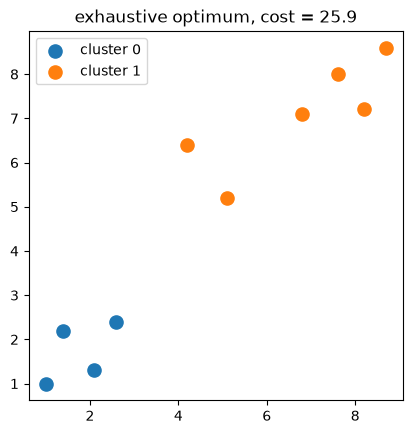

In [13]:
import matplotlib.pyplot as plt


def plot_clusters(D, blocks, title):
    colors = ["tab:blue", "tab:orange", "tab:green"]
    for r, block in enumerate(blocks):
        plt.scatter([D[i][0] for i in block], [D[i][1] for i in block],
                    color=colors[r % len(colors)], s=90, label=f"cluster {r}")
    plt.legend()
    plt.title(title)
    plt.gca().set_aspect("equal")
    plt.show()


plot_clusters(D, best, f"exhaustive optimum, cost = {best_cost:.1f}")


## 8. Comparing with k-means

k-means is greedy: it alternates "assign each point to its nearest centroid" and
"move each centroid to the mean of its cluster", so it stops at the first
partition that no single move improves. That is a **local** minimum. Since the
global optimum is known here, we can check whether the greedy algorithm found
it:


In [14]:
from sklearn.cluster import KMeans

for seed in range(3):
    km = KMeans(n_clusters=2, n_init=1, random_state=seed).fit(D)
    blocks = [[i for i in range(len(D)) if km.labels_[i] == b] for b in range(2)]
    cost = sum(wcss(D, block) for block in blocks)
    print(f"random_state = {seed}: cost = {cost:7.2f}   clusters = {blocks}")

print(f"exhaustive optimum: cost = {best_cost:7.2f}")


random_state = 0: cost =   25.94   clusters = [[4, 5, 6, 7, 8, 9], [0, 1, 2, 3]]
random_state = 1: cost =   25.94   clusters = [[4, 5, 6, 7, 8, 9], [0, 1, 2, 3]]
random_state = 2: cost =   25.94   clusters = [[4, 5, 6, 7, 8, 9], [0, 1, 2, 3]]
exhaustive optimum: cost =   25.94


Every k-means cost is $\ge$ the exhaustive cost, and on this easy data set they
happen to agree with it. Had one of them been larger, we would have caught a
local minimum, something impossible to detect without a reference value. For
real data sets that reference cannot be computed, which is why practice uses
several restarts (`n_init`) and a good initialization (k-means++), and why the
number of clusters is chosen by a separate criterion (silhouette, elbow) rather
than by the cost alone.

## 9. Several clusters, and the Stirling count

The same recursion handles $k$ labels, with two changes.

* A labeling counts only if *all* $k$ labels appear, otherwise some cluster is
  empty.
* Relabelings must not be counted again. Fixing the label of point 0 to 0 is not
  enough, because the remaining labels can still be permuted, which over-counts
  by $(k-1)!$. The standard fix is a **restricted growth condition**: a new
  point may take an already used label, or the next unused one, but never a
  label that has not appeared yet. Then every partition corresponds to exactly
  one labeling, and the count should be $S(n,k)$.


In [15]:
def clusterings_k(n, k):
    """All partitions of {0,...,n-1} into exactly k non-empty blocks."""
    z = [0] * n                                   # point 0 is in block 0

    def rec(i):
        if i == n:
            if max(z) + 1 == k:                   # all k blocks are used
                yield [[j for j in range(n) if z[j] == b] for b in range(k)]
            return
        for label in range(min(max(z[:i]) + 2, k)):   # old labels, or the next one
            z[i] = label
            yield from rec(i + 1)

    yield from rec(1)


In [16]:
for n in range(3, 8):
    print(f"n = {n}:", [sum(1 for _ in clusterings_k(n, k)) for k in range(1, n + 1)])


n = 3: [1, 3, 1]
n = 4: [1, 7, 6, 1]
n = 5: [1, 15, 25, 10, 1]
n = 6: [1, 31, 90, 65, 15, 1]
n = 7: [1, 63, 301, 350, 140, 21, 1]


Compare with the rows of the Stirling triangle, computed with the recurrence:


In [17]:
def S(n, k):
    if k > n:
        return 0
    if k == 1 or k == n:
        return 1
    return k * S(n - 1, k) + S(n - 1, k - 1)


for n in range(3, 8):
    print(f"n = {n}:", [S(n, k) for k in range(1, n + 1)])


n = 3: [1, 3, 1]
n = 4: [1, 7, 6, 1]
n = 5: [1, 15, 25, 10, 1]
n = 6: [1, 31, 90, 65, 15, 1]
n = 7: [1, 63, 301, 350, 140, 21, 1]


The two triangles are equal, so the enumeration is correct, and the $k^n$
labelings collapse to $S(n,k)$ partitions. The size of the search space for a
real problem is another matter:


In [18]:
print(f"{'n':>4} {'k':>3} {'k**n':>12} {'S(n,k)':>12}")
for n, k in [(10, 2), (10, 3), (15, 3), (20, 4), (50, 5), (150, 3)]:
    print(f"{n:>4} {k:>3} {k ** n:>12.2e} {S(n, k):>12.2e}")


   n   k         k**n       S(n,k)
  10   2     1.02e+03     5.11e+02
  10   3     5.90e+04     9.33e+03
  15   3     1.43e+07     2.38e+06
  20   4     1.10e+12     4.52e+10
  50   5     8.88e+34     7.40e+32
 150   3     3.70e+71     6.17e+70


$S(150,3)\approx 6.2\times10^{70}$: no exhaustive search will ever finish. In
practice, k-means, hierarchical clustering or LVQ produce a *good* partition in
polynomial time, and we accept that it may not be the best one.

## 10. What we learned

* Exhaustive search is simple and exact; it needs only the recursion of the
  SAT-Table notebook plus a cost function.
* The number of candidates is $S(n,2)=2^{n-1}-1$ for two clusters and $S(n,k)$
  in general. The ratio $k^n/S(n,k)\approx k!$ is the label symmetry, and
  labelings with empty clusters are not clusterings.
* WCSS (centroid form) and the sum of squared pairwise distances define the same
  objective up to the factor $|C|$; the centroid form is cheaper.
* The exhaustive optimum is the benchmark that tells us whether a heuristic has
  stopped at a local minimum.
* Distances must be written for vectors, coordinate by coordinate; the scalar
  formula is only a special case.

## Exercises

1. Rewrite `bf_clustering_2` so that it also returns the *second* best
   clustering. Why might that be useful?
2. Use `clusterings_k` and `wcss` to write `bf_clustering_k(D, k)` and run it on
   the ten points of Section 7 with $k=3$. (Warning: $S(10,3)=9330$ candidates.)
3. Replace WCSS by the sum of *distances* (not squared) and check whether the
   optimal 2-clustering of Section 7 changes; Hastie et al., Sec. 14.3.5, use
   this variant.
4. Add a pruning rule: as soon as the partial cost of a cluster exceeds the best
   total cost found so far, abandon the branch. Where in the recursion does the
   test go? How much does it save for $n=12$?
5. Prove the identity between the pairwise sum and $|C|\,W(C)$ by expanding
   $\sum_{i<j}\|\mathbf{x}_i-\mathbf{x}_j\|^2$.
6. Why is the label symmetry exactly $k!$ and not $k^n$? When is $k^n/S(n,k)$
   much larger than $k!$?
